# Used Car Price Prediction
**Linear Regression and Random Forest on CarDekho listings** &nbsp;·&nbsp; Machine Learning mini project (CA4) &nbsp;·&nbsp; TY DS, University Dept. of ICT, MGM University

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AbdulRafe8869/used-car-price-band-prediction/blob/main/notebooks/Used_Car_Price_Prediction.ipynb)

| Team | Roll no. | Part presented |
|---|---|---|
| Abdul Rafe | 2407070 | Student 1 · Dataset description and preprocessing (Parts 1-2) |
| Muntasir Ali Khan | 2407019 | Student 2 · ML model implementation (Part 3) |
| Shaikh Abdullah Saud | 2407040 | Student 3 · Evaluation, results and overall demonstration (Parts 4-5) |

Guide: Ms. Priyanka Hajare

**Problem.** Predict the **exact selling price, in rupees,** of a used car from its brand, model, age, mileage, fuel,
transmission, seller type and owner history. This is a **regression** problem. Next to every price we also show a
*likely price range*, because no model with only seven inputs can be exact to the rupee.

**How this notebook maps to the marking scheme**

| Marking parameter (2 marks each) | Where |
|---|---|
| 1. Dataset description and understanding | Part 1 |
| 2. Data preprocessing and preparation | Part 2 |
| 3. ML model implementation | Part 3 |
| 4. Model performance and evaluation | Part 4 |
| 5. Live demonstration, team contribution and viva | Part 5 (+ the Streamlit app and `docs/VIVA_GUIDE.md`) |

*Run time: about 10-12 minutes end to end (the Random Forest Grid Search is most of it). Everything is seeded
(`random_state=42`), so you get the same numbers every time.*

In [1]:
# Run this cell first. It works on your computer (from the repo folder or notebooks/) and on Google Colab.
import os, sys, subprocess

REPO_URL = "https://github.com/AbdulRafe8869/used-car-price-band-prediction.git"   # set by scripts/set_github_user.py
REPO_DIR = "used-car-price-band-prediction"

if not os.path.exists("src/config.py"):
    if os.path.exists("../src/config.py"):                 # notebook opened from the notebooks/ folder
        os.chdir("..")
    elif "YOUR-" + "USERNAME" in REPO_URL:          # (split on purpose so set_github_user.py leaves it alone)
        raise RuntimeError("Edit REPO_URL above to point to your GitHub repository, then run this cell again.")
    else:                                                   # Google Colab: fetch the project
        if not os.path.exists(REPO_DIR):
            subprocess.run(["git", "clone", REPO_URL], check=True)
        os.chdir(REPO_DIR)
sys.path.insert(0, os.getcwd())
print("repo folder:", os.path.basename(os.getcwd()))

repo folder: used-car-price-band-prediction


In [2]:
%matplotlib inline
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline

from src import config as cfg
from src import data_prep as dp
from src import features as ft
from src import pipeline as pl
from src import evaluate as ev
from src import predict as pr
from src import train as tr
from src import make_figures as mf
from src import visualize as viz              # chart style: validated colour-blind-safe palette

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


---
## Part 1 · Dataset description and understanding &nbsp;(2 marks)
*Presented by Student 1*

| Item | Answer |
|---|---|
| **Source** | Kaggle, *Vehicle dataset from CarDekho* by `nehalbirla` (file `CAR DETAILS FROM CAR DEKHO.csv`) |
| **Purpose** | Used-car listings from CarDekho (India) with the seller's asking price; commonly used for price estimation |
| **Records** | 4,340 listings |
| **Features** | 8 columns: 7 inputs and 1 target |
| **Target** | `selling_price` in Indian rupees. It is a **continuous number**, so the model predicts the exact price (regression). We do not group prices into bands. |
| **Type of data** | Numeric (`year`, `km_driven`, `selling_price`), categorical (`fuel`, `seller_type`, `transmission`, `owner`) and text (`name`) |

In [3]:
raw = dp.load_raw()
print(f"Records: {raw.shape[0]:,}    Columns: {raw.shape[1]}")
print("\nSample records (first 8 rows):")
display(raw.head(8))
print("Data types:")
display(raw.dtypes.rename("dtype").to_frame().T)

Records: 4,340    Columns: 8

Sample records (first 8 rows):


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner


Data types:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
dtype,str,int64,int64,int64,str,str,str,str


In [4]:
dictionary = pd.DataFrame([
    ("name",          "text",        "Listing title: brand + model + variant, e.g. 'Maruti Swift Dzire VDI'"),
    ("year",          "numeric",     "Year the car was manufactured"),
    ("selling_price", "numeric",     "TARGET. Asking price in rupees (INR)"),
    ("km_driven",     "numeric",     "Kilometres on the odometer: a wear indicator"),
    ("fuel",          "categorical", "Petrol, Diesel, CNG, LPG or Electric"),
    ("seller_type",   "categorical", "Individual, Dealer or Trustmark Dealer"),
    ("transmission",  "categorical", "Manual or Automatic"),
    ("owner",         "categorical", "Ownership history: First, Second, Third, Fourth & Above, or Test Drive Car"),
], columns=["Column", "Type", "Meaning"])
display(dictionary.style.hide(axis="index"))

print("Numeric summary:")
display(raw[["year", "selling_price", "km_driven"]].describe().round(0))
print("Categorical columns:")
for c in ["fuel", "seller_type", "transmission", "owner"]:
    print(f"  {c:13s}", raw[c].value_counts().to_dict())

Column,Type,Meaning
name,text,"Listing title: brand + model + variant, e.g. 'Maruti Swift Dzire VDI'"
year,numeric,Year the car was manufactured
selling_price,numeric,TARGET. Asking price in rupees (INR)
km_driven,numeric,Kilometres on the odometer: a wear indicator
fuel,categorical,"Petrol, Diesel, CNG, LPG or Electric"
seller_type,categorical,"Individual, Dealer or Trustmark Dealer"
transmission,categorical,Manual or Automatic
owner,categorical,"Ownership history: First, Second, Third, Fourth & Above, or Test Drive Car"


Numeric summary:


,year,selling_price,km_driven
count,4340.0,4340.0,4340.0
mean,2013.0,504127.0,66216.0
std,4.0,578549.0,46644.0
min,1992.0,20000.0,1.0
25%,2011.0,208750.0,35000.0
50%,2014.0,350000.0,60000.0
75%,2016.0,600000.0,90000.0
max,2020.0,8900000.0,806599.0


Categorical columns:
  fuel          {'Diesel': 2153, 'Petrol': 2123, 'CNG': 40, 'LPG': 23, 'Electric': 1}
  seller_type   {'Individual': 3244, 'Dealer': 994, 'Trustmark Dealer': 102}
  transmission  {'Manual': 3892, 'Automatic': 448}
  owner         {'First Owner': 2832, 'Second Owner': 1106, 'Third Owner': 304, 'Fourth & Above Owner': 81, 'Test Drive Car': 17}


**The target: selling price.** Prices run from Rs 20,000 to Rs 8,900,000. The median car costs
Rs 350,000 but the mean is Rs 473,913: a few luxury cars pull the average up. The distribution is strongly
**right-skewed** (skewness 5.5; 0 would be symmetric). This matters for how we train the models, and we deal with it
in Part 2.7. (Numbers below are for the cleaned data of Part 2.)

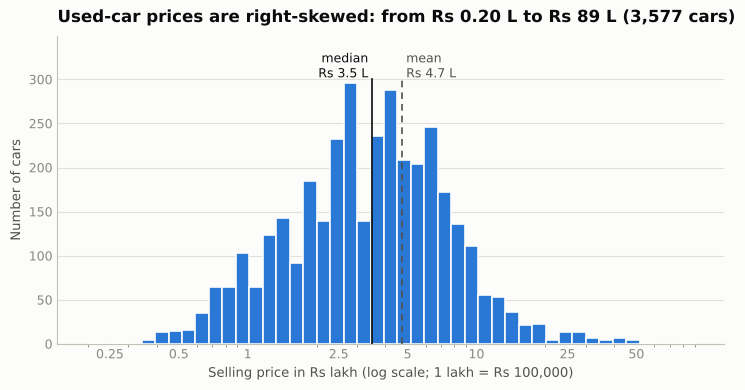

In [5]:
clean_df, report = dp.clean(raw)
_ = viz.fig_price_distribution(clean_df)

---
## Part 2 · Data preprocessing and preparation &nbsp;(2 marks)
*Presented by Student 1*

The order is deliberate: **clean → split → everything that learns from data happens inside a Pipeline**, so no information
from the test set can leak into training.

| Rubric item | Section |
|---|---|
| Checking and handling missing values | 2.1 |
| Removing duplicate or irrelevant data | 2.2 |
| Handling outliers | 2.5 |
| Encoding categorical variables | 2.8 |
| Feature scaling / normalisation | 2.8 |
| Feature selection or feature engineering | 2.6 and 2.9 |
| Splitting into training and testing data | 2.4 |
| Any other preprocessing | 2.3 (impossible values, tidy text), 2.7 (log of the price), 2.10 (EDA) |

### 2.1 Missing values

In [6]:
missing = raw.isna().sum()
display(missing.rename("missing values").to_frame().T)
print("Total missing cells:", int(missing.sum()))

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
missing values,0,0,0,0,0,0,0,0


Total missing cells: 0


There are **no missing values** in this file. We still put a median imputer (numbers) and a most-frequent imputer
(categories) inside the pipeline, so the app will not crash if a field is ever left empty, and the imputers are
fitted on training data only.

### 2.2 Duplicate and irrelevant data

In [7]:
n_dup = int(raw.duplicated().sum())
print(f"{n_dup} exact duplicate rows = {100 * n_dup / len(raw):.1f}% of the file")
display(raw[raw.duplicated(keep=False)].sort_values(list(raw.columns)).head(6))

# Why duplicates must go BEFORE the split: demonstrate the leak we would otherwise create.
bad_train, bad_test = train_test_split(raw, test_size=cfg.TEST_SIZE, random_state=cfg.RANDOM_STATE)
seen = set(map(tuple, bad_train.values))
leak = np.mean([tuple(r) in seen for r in bad_test.values])
print(f"\nIf we split first and de-duplicate later, {leak:.1%} of the 'unseen' test cars would be exact copies "
      f"of training cars and the test score would be inflated.")

763 exact duplicate rows = 17.6% of the file


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
3912,Ambassador CLASSIC 1500 DSL AC,2005,120000,50000,Diesel,Individual,Manual,Second Owner
4016,Ambassador CLASSIC 1500 DSL AC,2005,120000,50000,Diesel,Individual,Manual,Second Owner
99,Audi A4 2.0 TDI 177 Bhp Premium Plus,2013,1150000,53000,Diesel,Dealer,Automatic,First Owner
2578,Audi A4 2.0 TDI 177 Bhp Premium Plus,2013,1150000,53000,Diesel,Dealer,Automatic,First Owner
554,Audi A4 3.0 TDI Quattro,2013,1580000,86000,Diesel,Dealer,Automatic,First Owner
573,Audi A4 3.0 TDI Quattro,2013,1580000,86000,Diesel,Dealer,Automatic,First Owner



If we split first and de-duplicate later, 25.8% of the 'unseen' test cars would be exact copies of training cars and the test score would be inflated.


**Irrelevant data:** there is no ID or constant column to drop. The raw `name` text is not fed to the model as-is; it is
turned into brand, model and keyword features (2.6).

### 2.3 Clean: tidy text, remove duplicates, check impossible values

In [8]:
clean_df, report = dp.clean(raw)
print(json.dumps({k: report[k] for k in ["rows_raw", "duplicates_removed", "duplicates_pct", "invalid_rows_removed",
                                         "rows_clean"]}, indent=2))

{
  "rows_raw": 4340,
  "duplicates_removed": 763,
  "duplicates_pct": 17.58,
  "invalid_rows_removed": 0,
  "rows_clean": 3577
}


Impossible values (zero or negative price, negative distance, year after 2020 or before 1990) are checked and logged;
there are none. After removing 763 duplicates, **3,577 clean listings** remain.

### 2.4 Splitting into training and testing data (80:20, balanced by price)

In [9]:
train_df, test_df = dp.split(clean_df)
X_train, y_train = dp.xy(train_df)
X_test,  y_test  = dp.xy(test_df)
print(f"train: {len(train_df):,} rows   test: {len(test_df):,} rows")
q = [0.1, 0.25, 0.5, 0.75, 0.9]
display(pd.DataFrame({"train": train_df[cfg.TARGET_COL].quantile(q), "test": test_df[cfg.TARGET_COL].quantile(q)})
        .rename_axis("price percentile").round(0))

train: 2,861 rows   test: 716 rows


,train,test
price percentile,,
0.10,110000.0,110000.0
0.25,200000.0,200000.0
0.50,350000.0,350000.0
0.75,600000.0,580000.0
0.90,875000.0,855000.0


There are no classes to stratify on, so we sort the cars into **10 equal-sized price groups** (deciles) and split each
group 80:20. Cheap, mid-range and luxury cars therefore appear in the test set in the same proportion as in the training
set, and the two price distributions in the table match. The test set is used **once**, in Part 4.

### 2.5 Outliers

,feature,lower fence,upper fence,train max,values clipped
0,car_age,-14.0,28.0,24.0,0
1,km_driven,-126000.0,252000.0,350000.0,9
2,km_per_year,-19000.0,39916.7,120000.0,36
3,owner_count,-2.0,5.0,4.0,0


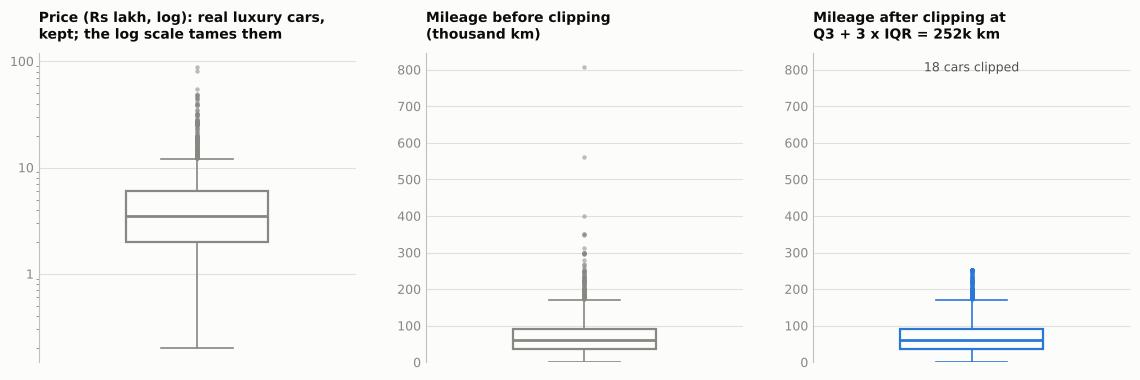

In [10]:
eng = ft.FeatureEngineer().fit_transform(X_train)                 # engineered columns (see 2.6)
clipper = ft.IQRClipper(k=cfg.IQR_K).fit(eng[cfg.NUMERIC_FEATURES])
rows = []
for i, col in enumerate(cfg.NUMERIC_FEATURES):
    v = eng[col].astype(float)
    rows.append({"feature": col, "lower fence": clipper.lower_[i], "upper fence": clipper.upper_[i],
                 "train max": v.max(), "values clipped": int(((v < clipper.lower_[i]) | (v > clipper.upper_[i])).sum())})
display(pd.DataFrame(rows).round(1))
_ = viz.fig_outliers(clean_df, train_df)

**Rule for the inputs:** values beyond *Q3 + 3 x IQR* (Tukey's "far-out" fence) are **pulled back to the fence**, not
deleted. The most extreme case is a car listed at 806,599 km, almost certainly a typing error. Clipping stops one value from
dragging the scaler and the Linear Regression weights. The fences are learned on the training set only.

**The target price is not clipped or deleted.** A Rs 89 lakh car is a real car, and removing it would make the model
unable to price luxury cars at all. Instead, the log transform in 2.7 stops these few very high prices from dominating
the training.

### 2.6 Feature engineering

In [11]:
display(pd.concat([X_train.head(5)[["name", "year", "km_driven", "owner"]].reset_index(drop=True),
                   eng.head(5)[["car_age", "km_per_year", "owner_count", "brand", "brand_tier", "model", "name_keywords"]]],
                  axis=1))

,name,year,km_driven,owner,car_age,km_per_year,owner_count,brand,brand_tier,model,name_keywords
0,Hyundai Creta 1.4 EX Diesel,2020,10000,First Owner,0,10000.000000,1,Hyundai,Mid-range,Hyundai Creta,creta 1.4 ex diesel
1,Maruti Celerio VXI,2015,35000,First Owner,5,7000.000000,1,Maruti,Economy,Maruti Celerio,celerio vxi
2,Maruti Swift Dzire VDI,2017,66000,Third Owner,3,22000.000000,3,Maruti,Economy,Maruti Swift,swift dzire vdi
3,Tata Indica GLS BS IV,2010,70000,First Owner,10,7000.000000,1,Tata,Economy,Tata Indica,indica gls bs iv
4,Mercedes-Benz E-Class 230,1998,35000,Second Owner,22,1590.909091,2,Mercedes-Benz,Luxury,Mercedes-Benz E-Class,e class 230


| New feature | How it is built | Why |
|---|---|---|
| `car_age` | 2020 − `year` (2020 is the newest year in the data) | Price falls with age, and age is easier to learn than a calendar year |
| `km_per_year` | `km_driven` ÷ max(age, 1) | Usage intensity: 60,000 km on a 2-year-old car is very different from 60,000 km on a 12-year-old one |
| `owner_count` | First = 1 … Fourth & above = 4, Test drive = 0 | Ordered, so one number is enough |
| `brand`, `model` | Parsed from `name` (e.g. "Maruti", "Maruti Swift") | The biggest single price driver |
| `brand_tier` | Economy / Mid-range / Luxury (our own domain-knowledge grouping, listed in `src/config.py`) | Lets the model share what it learns across brands |
| `name_keywords` | Words after the brand, e.g. "dzire vdi" → 0/1 flags | Captures variant and trim level (e.g. "vdi", "titanium"); words seen < 10 times are ignored |

### 2.7 Transforming the target: predict log(price)

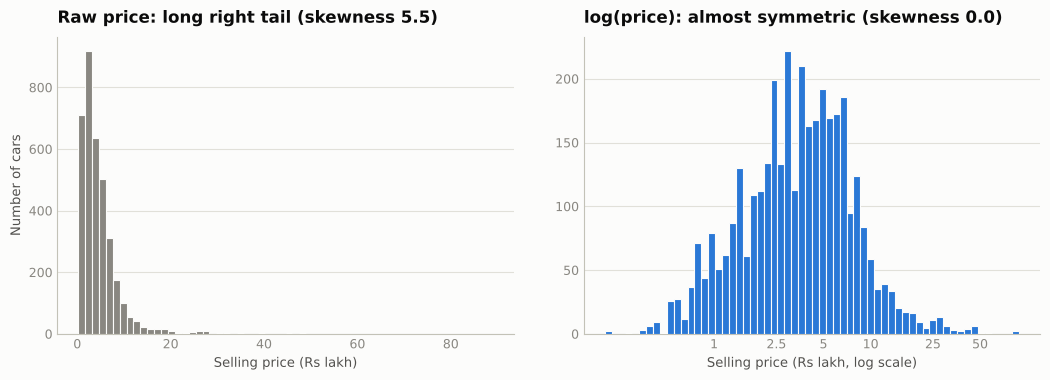

In [12]:
_ = viz.fig_target_transform(clean_df)

Prices are skewed (skewness 5.5), and a car's price changes by a **percentage** with age and mileage (a
3-year-old car is not "Rs 2 lakh cheaper" than a new one at every price level; it is roughly 15-20% cheaper). On the
log scale the skewness is -0.02 (almost symmetric) and those percentage effects become simple
additions, which suits a linear model.

So both models are **trained on log(price) and their output is converted back to rupees** with `exp()`. This is done by
scikit-learn's `TransformedTargetRegressor`, so the app and every metric work in plain rupees. A side effect: a
predicted price can never be negative. We tested the alternative in the bonus section (experiment D):
without the log, Linear Regression's typical error rises from 16% to
25% and it predicts 38 negative prices on the test set.

### 2.8 Encoding and scaling (inside the Pipeline)

In [13]:
prep = Pipeline([("features", ft.FeatureEngineer()), ("prep", pl.build_preprocessor())]).fit(X_train)
Xt = prep.transform(X_train)
Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
names = pl.transformed_feature_names(prep)
group = pd.Series([ev.feature_group(n, cfg.NUMERIC_FEATURES + cfg.CATEGORICAL_FEATURES) for n in names]).value_counts()
print(f"{X_train.shape[1]} raw inputs  ->  {Xt.shape[1]} model columns")
display(group.rename("columns").to_frame().T)
scaled = pd.DataFrame(Xt[:, :4], columns=names[:4])
print("Scaled numeric columns on the training set (should be mean ~ 0, std ~ 1):")
display(scaled.agg(["mean", "std"]).round(3))

7 raw inputs  ->  334 model columns


,name_keywords,model,brand,fuel,seller_type,brand_tier,transmission,car_age,km_driven,km_per_year,owner_count
columns,227,72,18,5,3,3,2,1,1,1,1


Scaled numeric columns on the training set (should be mean ~ 0, std ~ 1):


,car_age,km_driven,km_per_year,owner_count
mean,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0


* **Numeric** → median imputer → outlier clipping → `StandardScaler` (mean 0, std 1). Linear Regression needs this so
  that the weights are comparable and the penalty treats every feature fairly; Random Forest does not, but it is harmless.
* **Categorical** → most-frequent imputer → `OneHotEncoder`. Levels seen fewer than 10 times are pooled into one
  "infrequent" column, and unseen levels at prediction time are handled, so a brand-new model name cannot crash the app.
* **Keywords** → binary `CountVectorizer`.

Because all of this lives in one `Pipeline`, cross-validation re-fits every step on each training fold only (no leakage),
and the app reuses exactly the same fitted steps.

### 2.9 Feature selection

Drop one feature group at a time and re-run 5-fold CV on the TRAINING set (test set untouched).
Lower median % error is better; a positive change means the model got WORSE without that group:


group removed,Linear: median % error (CV),RF: median % error (CV),Linear: change (pts),RF: change (pts)
Full model (all features),15.400000,16.200000,0.000000,0.000000
Without: Name keywords (variant words),16.200000,17.800000,0.800000,1.500000
Without: Brand tier,15.700000,17.100000,0.300000,0.900000
"Without: Fuel, seller type, transmission",15.800000,16.800000,0.400000,0.500000
Without: Owner count,15.500000,16.600000,0.200000,0.300000
"Without: Age and usage (age, km, km per year)",24.200000,23.100000,8.800000,6.800000
"Without: Car identity (brand, model, tier, keywords)",28.300000,29.700000,13.000000,13.500000


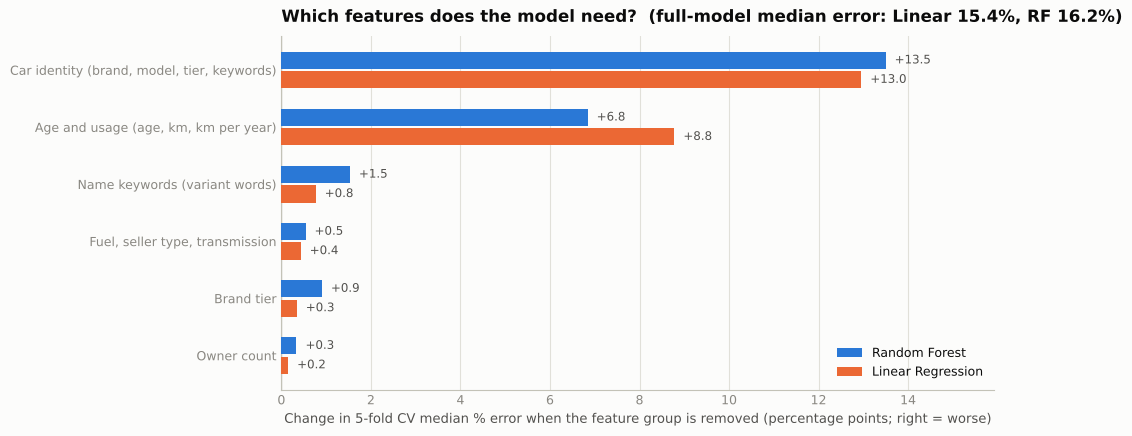

In [14]:
exp = json.loads((cfg.REPORTS_DIR / "experiments.json").read_text())
ablation = pd.DataFrame(exp["ablation"])
show = pd.DataFrame({
    "group removed": ablation["group"],
    "Linear: median % error (CV)": (ablation["cv_medape_linear_regression"] * 100).round(1),
    "RF: median % error (CV)":     (ablation["cv_medape_random_forest"] * 100).round(1),
    "Linear: change (pts)": (ablation["delta_linear_regression"] * 100).round(1),
    "RF: change (pts)":     (ablation["delta_random_forest"] * 100).round(1),
})
print("Drop one feature group at a time and re-run 5-fold CV on the TRAINING set (test set untouched).")
print("Lower median % error is better; a positive change means the model got WORSE without that group:")
display(show.style.hide(axis="index"))
_ = viz.fig_ablation(ablation)

Reading the table: removing **car identity** (brand, model, tier, keywords) makes the typical error about
13 points worse, and removing **age and usage** about 7-9 points worse;
those two groups carry the model. Every other group changes the typical error by less than 2 points, so they are weak but
harmless and we keep them. Importance-based analysis of the fitted models is shown in Part 4.

### 2.10 Exploratory plots (cleaned data)

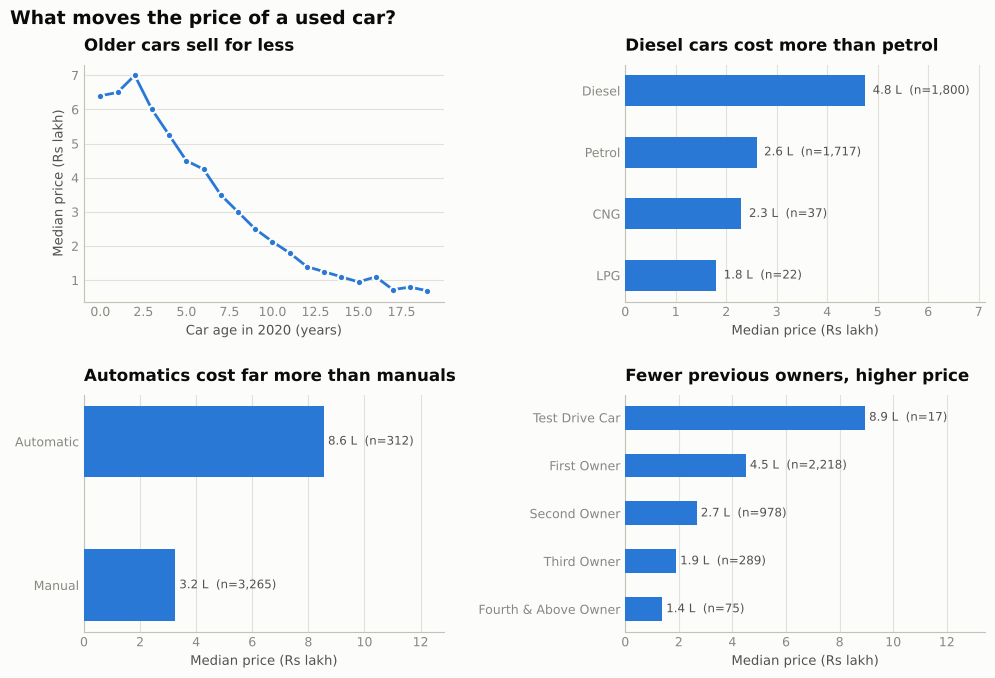

In [15]:
_ = viz.fig_price_drivers(clean_df)

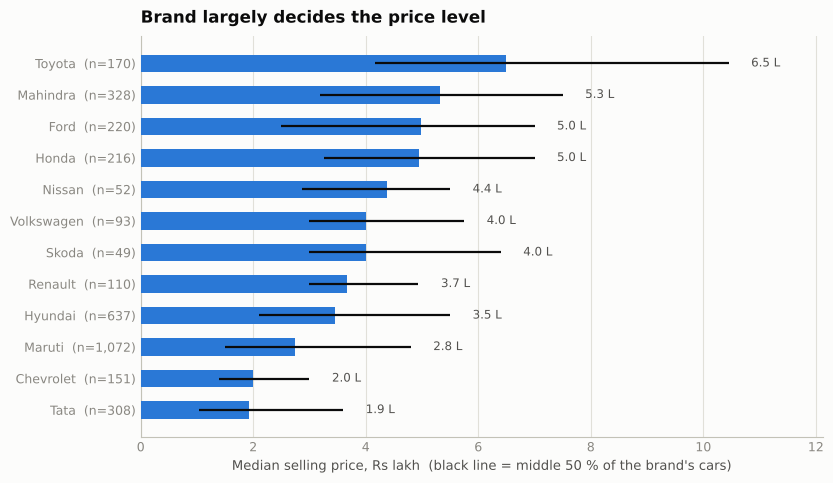

In [16]:
_ = viz.fig_price_by_brand(clean_df)

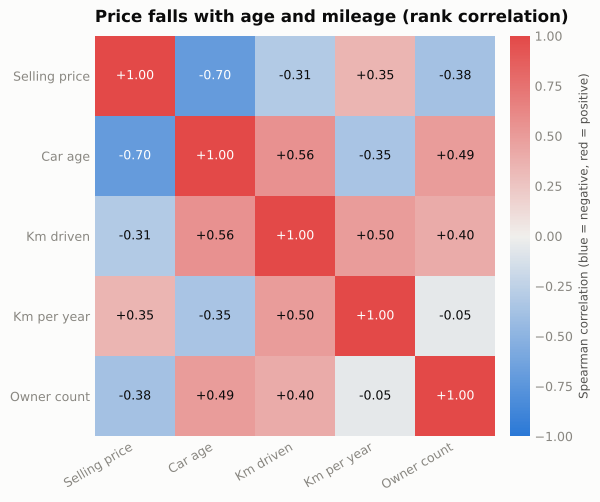

In [17]:
_ = viz.fig_correlation(clean_df)

**What the plots say:** price is heavily right-skewed; newer cars and lower mileage go with higher prices (price
and year have a Spearman correlation of +0.70, price and kilometres -0.31); automatic cars have a median price of Rs 8.6 lakh
against Rs 3.3 lakh for manual, and diesel cars Rs 4.8 lakh against Rs 2.6 lakh for petrol (partly because diesel cars tend to be larger, newer models);
and brand separates prices strongly: Tata and Chevrolet are the cheapest large brands (median about Rs 2 lakh),
Maruti (the largest brand) sits at Rs 2.75 lakh, Toyota at Rs 6.5 lakh and Audi at Rs 15.8 lakh.

---
## Part 3 · ML model implementation &nbsp;(2 marks)
*Presented by Student 2*

**Why two algorithms?** A simple, explainable baseline and a flexible model, so the comparison tells us whether the
extra complexity is worth it. Random Forest is also the model used in five of the six 2025 papers we reviewed.

### Linear Regression with an L2 penalty (baseline)
It predicts log(price) as a weighted sum of the features, *log price = b0 + b1·x1 + b2·x2 + …*, and then converts it back
to rupees. Training chooses the weights that **minimise the squared error plus a penalty on the size of the weights**
(*alpha* × the sum of squared weights; this is what the literature calls Ridge regression). A larger *alpha* shrinks the weights
more, which limits overfitting when many one-hot columns are correlated. It draws a straight-line relationship and each weight
has a direct meaning, so it is easy to explain.

### Random Forest Regressor (main non-linear model)
It builds many decision trees, each on a random sample of the cars and a random subset of features at every split.
Each tree predicts a price (the average of the cars in the leaf it reaches) and the forest returns the **average of all
the trees**. Averaging many different trees reduces overfitting, and trees can capture effects such as "age matters more for premium brands".
Tuned settings: `n_estimators` (number of trees), `max_depth`, `min_samples_leaf`, `max_features`.

### Training process
1. **Dummy baseline**: always predict the average training price. The floor any real model must beat.
2. **Grid Search** over the hyper-parameters, scored by **5-fold cross-validation on the training set only**.
3. Choose by cross-validated **RMSLE** (root mean squared *log* error, which behaves like a typical percentage error, so
   a Rs 20,000 miss on a cheap car counts as much as a Rs 2 lakh miss on an expensive one). R² and MAE are recorded too.
   The winner is refit on the full training set. The test set plays no part in these choices.

In [18]:
dummy = pl.make_dummy().fit(X_train, y_train)

cv = KFold(n_splits=cfg.CV_FOLDS, shuffle=True, random_state=cfg.RANDOM_STATE)
SCORING = {"rmsle": "neg_root_mean_squared_log_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

def run_grid(name, pipeline, grid):
    search = GridSearchCV(pipeline, grid, cv=cv, scoring=SCORING, refit="rmsle", n_jobs=-1, return_train_score=True)
    n_fits = int(np.prod([len(v) for v in grid.values()])) * cfg.CV_FOLDS
    print(f"{name}: {n_fits} fits ...", flush=True)
    search.fit(X_train, y_train)
    print(f"{name}: best CV RMSLE = {-search.best_score_:.4f}   best params = {search.best_params_}")
    return search

lin_search = run_grid("Linear Regression", pl.make_linear_regression(), cfg.LINEAR_GRID)

Linear Regression: 40 fits ...


Linear Regression: best CV RMSLE = 0.2823   best params = {'model__regressor__alpha': 1}


In [19]:
rf_search = run_grid("Random Forest", pl.make_random_forest(), cfg.RF_GRID)   # a few minutes

Random Forest: 120 fits ...


Random Forest: best CV RMSLE = 0.2945   best params = {'model__regressor__max_depth': None, 'model__regressor__max_features': 0.33, 'model__regressor__min_samples_leaf': 1, 'model__regressor__n_estimators': 400}


Top 5 settings: linear_regression


params,cv_rmsle,cv_rmsle_std,cv_mae_rs,cv_r2,train_r2,rank
{'model__regressor__alpha': 1},0.282300,0.013600,94923.527300,0.795600,0.832700,1
{'model__regressor__alpha': 3},0.282800,0.013600,95022.128200,0.795100,0.820000,2
{'model__regressor__alpha': 0.3},0.282900,0.013200,95549.200600,0.792700,0.839200,3
{'model__regressor__alpha': 0.1},0.283300,0.012900,96002.401400,0.790000,0.841000,4
{'model__regressor__alpha': 0.03},0.283800,0.012800,96224.154400,0.788400,0.841300,5


Top 5 settings: random_forest


params,cv_rmsle,cv_rmsle_std,cv_mae_rs,cv_r2,train_r2,rank
"{'model__regressor__max_depth': None, 'model__regressor__max_features': 0.33, 'model__regressor__min_samples_leaf': 1, 'model__regressor__n_estimators': 400}",0.294500,0.004000,100757.348200,0.773700,0.945100,1
"{'model__regressor__max_depth': None, 'model__regressor__max_features': 0.33, 'model__regressor__min_samples_leaf': 1, 'model__regressor__n_estimators': 200}",0.294700,0.004200,101110.138200,0.770200,0.943100,2
"{'model__regressor__max_depth': None, 'model__regressor__max_features': 0.2, 'model__regressor__min_samples_leaf': 1, 'model__regressor__n_estimators': 400}",0.294900,0.005800,101864.089700,0.760200,0.940600,3
"{'model__regressor__max_depth': None, 'model__regressor__max_features': 0.2, 'model__regressor__min_samples_leaf': 1, 'model__regressor__n_estimators': 200}",0.294900,0.005800,101766.765000,0.762600,0.940300,4
"{'model__regressor__max_depth': 25, 'model__regressor__max_features': 0.2, 'model__regressor__min_samples_leaf': 1, 'model__regressor__n_estimators': 400}",0.295200,0.005300,101775.822800,0.760700,0.940000,5


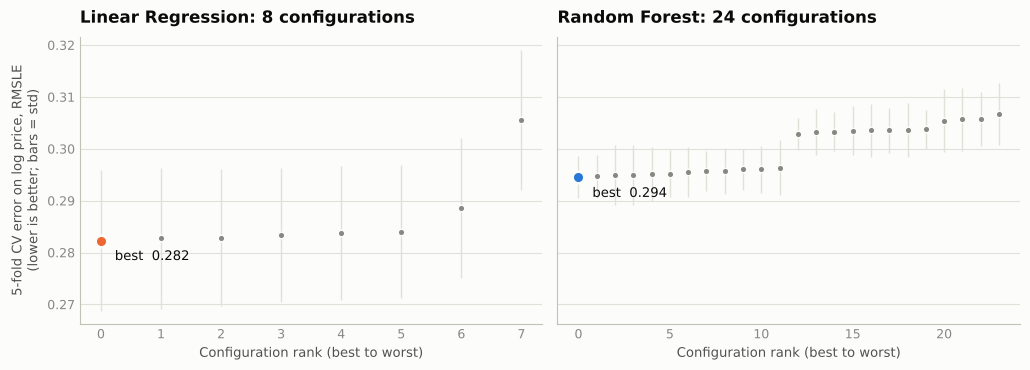

In [20]:
cv_tables = {"linear_regression": tr.save_cv_table(lin_search, os.devnull),
             "random_forest": tr.save_cv_table(rf_search, os.devnull)}
for key, t in cv_tables.items():
    print(f"Top 5 settings: {key}")
    display(t.head(5).round(4).style.hide(axis="index"))
_ = viz.fig_grid_search(cv_tables)

**Selected settings.** Linear Regression: `alpha = 1`. Random Forest:
400 trees, `max_depth = None` (no limit),
`max_features = 0.33`, `min_samples_leaf = 1`.

Cross-validated RMSLE on the training set (lower is better): Linear Regression **0.282**,
Random Forest **0.294**; cross-validated R² 0.796 against 0.774.
The model is chosen on these numbers, never on the test set.

---
## Part 4 · Model performance and evaluation &nbsp;(2 marks)
*Presented by Student 3*

This is the first and only time the 716 test cars are used. This is a **regression** problem, so we report:

| Metric | Meaning |
|---|---|
| **R²** | Share of the variation in price the model explains (1 = perfect, 0 = no better than always guessing the average) |
| **MAE** (mean absolute error) | Average miss, in rupees |
| **RMSE** | Like MAE but punishes big misses more, in rupees |
| **Median % error** | The typical miss as a share of the real price: half of the cars are predicted closer than this |
| **Mean % error (MAPE)** | Average of the same, pulled up by a few large misses |
| **Within ±10% / ±20%** | Share of cars priced within that distance of the real price |

In [21]:
models = {"dummy": dummy, "linear_regression": lin_search.best_estimator_, "random_forest": rf_search.best_estimator_}
REAL = ("linear_regression", "random_forest")
preds = {k: m.predict(X_test) for k, m in models.items()}
results = {}
for k, m in models.items():
    results[k] = ev.regression_metrics(y_test, preds[k])
    results[k]["train_r2"] = ev.regression_metrics(y_train, m.predict(X_train))["r2"]
    results[k]["train_mape"] = ev.regression_metrics(y_train, m.predict(X_train))["mape"]

names_ = {"dummy": "Average-price baseline", "linear_regression": "Linear Regression", "random_forest": "Random Forest"}
table = pd.DataFrame({
    "R2":                {names_[k]: r["r2"] for k, r in results.items()},
    "MAE (Rs)":          {names_[k]: r["mae_rs"] for k, r in results.items()},
    "RMSE (Rs)":         {names_[k]: r["rmse_rs"] for k, r in results.items()},
    "Median % error":    {names_[k]: 100 * r["median_ape"] for k, r in results.items()},
    "Mean % error":      {names_[k]: 100 * r["mape"] for k, r in results.items()},
    "Within +-10%":      {names_[k]: 100 * r["within_10pct"] for k, r in results.items()},
    "Within +-20%":      {names_[k]: 100 * r["within_20pct"] for k, r in results.items()},
    "Train R2":          {names_[k]: r["train_r2"] for k, r in results.items()},
})
display(table.round({"R2": 3, "MAE (Rs)": 0, "RMSE (Rs)": 0, "Median % error": 1, "Mean % error": 1,
                     "Within +-10%": 1, "Within +-20%": 1, "Train R2": 3}))

,R2,MAE (Rs),RMSE (Rs),Median % error,Mean % error,Within +-10%,Within +-20%,Train R2
Average-price baseline,-0.000,293893.0,504549.0,58.0,122.4,10.1,21.4,0.000
Linear Regression,0.871,89212.0,181250.0,15.5,21.5,33.2,62.0,0.837
Random Forest,0.834,98562.0,205328.0,16.3,23.0,31.7,59.2,0.952


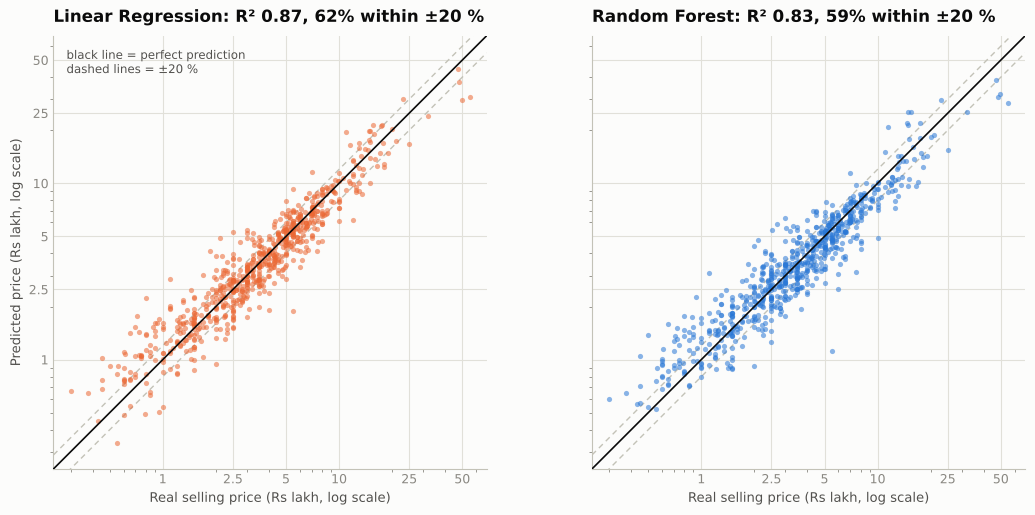

In [22]:
_ = viz.fig_predicted_vs_actual(y_test, {k: preds[k] for k in REAL}, results)

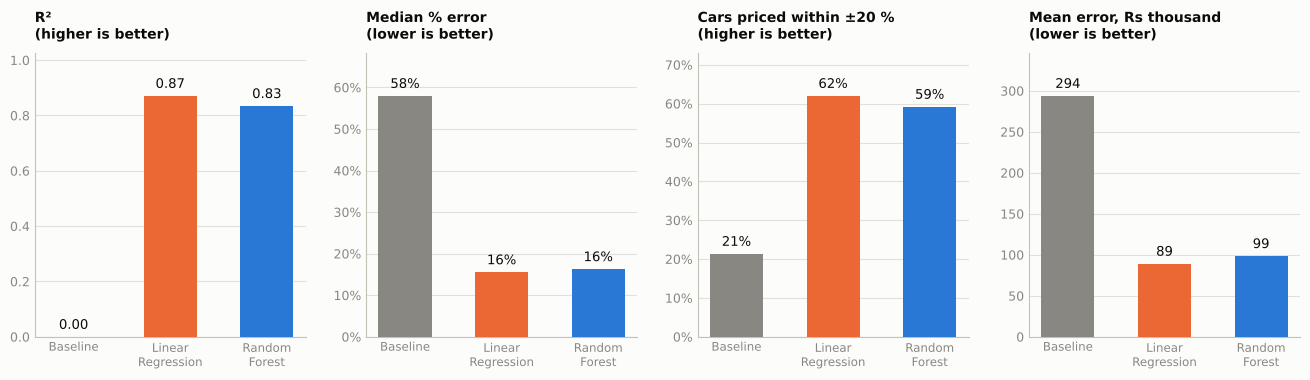

In [23]:
_ = viz.fig_model_comparison(results)

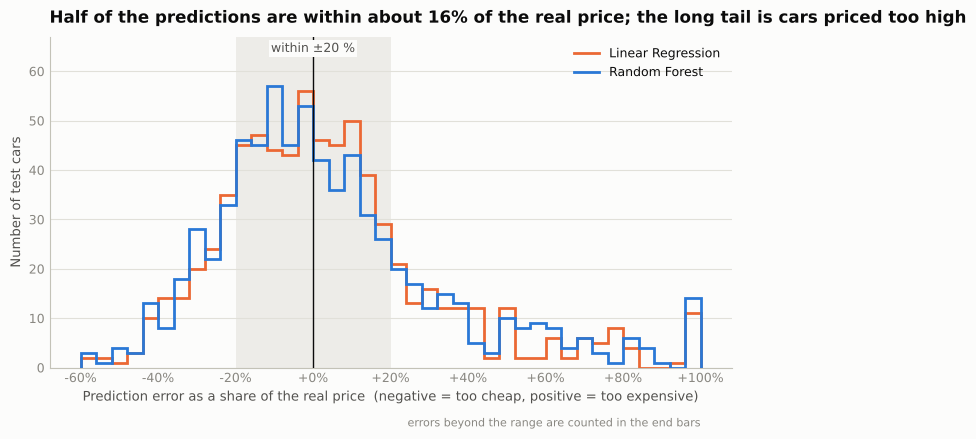

In [24]:
_ = viz.fig_error_distribution(y_test, {k: preds[k] for k in REAL})

In [25]:
sample = test_df.sample(10, random_state=cfg.RANDOM_STATE)[["name", "year", "km_driven", "fuel", "transmission"]].copy()
sample["real price"] = y_test[sample.index]
sample["Linear Regression"] = preds["linear_regression"][sample.index].round(-3)
sample["Random Forest"] = preds["random_forest"][sample.index].round(-3)
sample["Linear error"] = ((sample["Linear Regression"] / sample["real price"] - 1) * 100).round(0).astype(int).astype(str) + "%"
print("Ten random test cars: real price against the two predictions (rupees):")
display(sample.reset_index(drop=True).style.format({"real price": "{:,.0f}", "Linear Regression": "{:,.0f}",
                                                    "Random Forest": "{:,.0f}", "km_driven": "{:,.0f}"}).hide(axis="index"))

Ten random test cars: real price against the two predictions (rupees):


name,year,km_driven,fuel,transmission,real price,Linear Regression,Random Forest,Linear error
Maruti Swift 1.3 LXI,2007,"80,000",Petrol,Manual,"73,000","144,000","151,000",97%
Maruti Omni 8 Seater BSIV,2014,"57,112",Petrol,Manual,"250,999","282,000","270,000",12%
Ford Freestyle Trend Petrol BSIV,2019,"8,000",Petrol,Manual,"650,000","592,000","722,000",-9%
Honda Accord VTi-L (MT),2007,"80,000",Petrol,Manual,"200,000","243,000","223,000",22%
Ford Figo Diesel LXI,2011,"70,000",Diesel,Manual,"180,000","176,000","231,000",-2%
Tata Indica Vista Aqua 1.4 TDI,2008,"90,000",Diesel,Manual,"110,000","89,000","93,000",-19%
Maruti Estilo LXI,2014,"43,000",Petrol,Manual,"225,000","323,000","312,000",44%
Hyundai Santro Xing GL Plus,2012,"50,000",Petrol,Manual,"170,000","208,000","226,000",22%
Tata Manza Aura (ABS) Quadrajet BS IV,2012,"80,000",Diesel,Manual,"295,000","223,000","219,000",-24%
Maruti Alto LXi,2012,"50,000",Petrol,Manual,"150,000","183,000","177,000",22%


### Interpretation
* **Both models are far better than guessing the average.** The average-price baseline has R² of 0.00, a typical error of
  58% and a mean miss of Rs 293,893. Linear Regression reaches **R² 0.871**, a mean miss (MAE) of
  **Rs 89,212** and a typical error of **15.5%**; Random Forest reaches R² 0.834, MAE Rs 98,562 and a typical error of 16.3%.
* **What "typical error 15%" means in practice.** About half of the cars are priced within 16% of their real
  price, 62% within ±20% and 33% within ±10%. For a Rs 5 lakh car the
  typical miss is about Rs 75,000. The model gives a good estimate, not an exact valuation, which is why the app also shows the likely range (below).
* **Linear Regression is at least as good as Random Forest here.** On the same test cars the 95% bootstrap interval for the MAE gap
  (RF − Linear) is Rs 3,084 to Rs 15,786: Random Forest has the *higher* error and
  had the lower MAE in only 0.3% of the resamples. R² tells the same story
  (gap -0.067 to -0.008). For the typical % error the two are statistically tied (gap
  -0.8 to +2.4 points, which includes zero). So the honest reading is "Linear Regression is slightly ahead or
  tied", not "the more complex model wins".
* **Random Forest overfits; Linear Regression does not.** Random Forest has R² 0.952 on its training cars but 0.834 on
  unseen ones, and its mean % error is 7.9% on training cars against 23.0% on test cars. Linear Regression scores
  R² 0.837 on training and 0.871 on test (see the next point for why test is higher).
* **Test R² has real uncertainty.** With 716 test cars the 95% interval is 0.83-0.91 for
  Linear Regression and 0.79-0.88 for Random Forest. R² measured in rupees is sensitive to a handful of very
  expensive cars: the dearest test car costs Rs 55 lakh while training has cars up to Rs 89 lakh, which probably flatters the test
  R² a little. The percentage-error metrics are less affected, so we quote both.
* **Mean % error (21.5%) is higher than the median (15.5%)** because a minority of cars are missed by a lot.
  The histogram above shows a longer tail on the "predicted too high" side, mostly cheap cars (next section).

### How wide should the 'likely price range' be?

In [26]:
REAL_Y = y_test
intervals = {k: tr.price_interval(models[k], X_train, y_train) for k in REAL}      # out-of-fold, TRAINING data only
rows = []
for k in REAL:
    iv = intervals[k]
    lo, hi = preds[k] * iv["lower_multiplier"], preds[k] * iv["upper_multiplier"]
    rows.append({"model": names_[k], "range = prediction x": f"{iv['lower_multiplier']:.2f} to {iv['upper_multiplier']:.2f}",
                 "target coverage": f"{iv['coverage_target']:.0%}",
                 "share of TEST cars inside the range": f"{np.mean((REAL_Y >= lo) & (REAL_Y <= hi)):.1%}"})
display(pd.DataFrame(rows).style.hide(axis="index"))

model,range = prediction x,target coverage,share of TEST cars inside the range
Linear Regression,0.71 to 1.37,80%,80.4%
Random Forest,0.71 to 1.40,80%,77.9%


For every training car we predict its price with a model that **never saw that car** (cross-validation), compute
*real price ÷ predicted price*, and take the 10th and 90th percentiles. Multiplying a new prediction by these two numbers
gives a range that should contain about 80% of cars. The check on the untouched test set confirms it: the range holds
80.4% of test cars for Linear Regression (×0.71 to ×1.37) and 77.9% for Random Forest.
Example: a predicted Rs 5,00,000 becomes roughly Rs 353,932 to Rs 683,642. The range is wide, and that is the
honest message: with these seven inputs, two cars that look identical on paper can sell for quite different prices.

### What drives the price? (importance-based feature analysis)

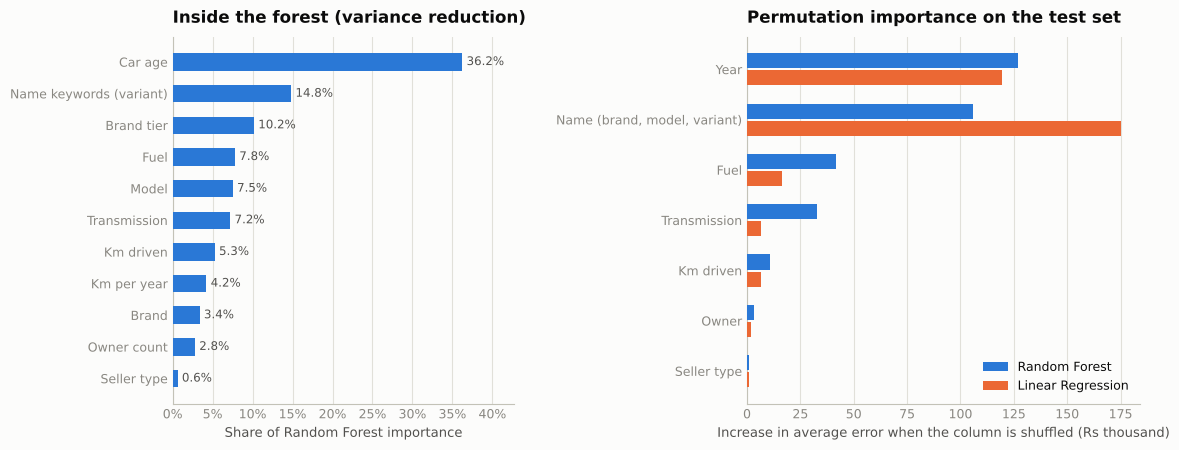

In [27]:
importance = {
    "rf_impurity_grouped":    ev.grouped_impurity_importance(models["random_forest"]).round(5).to_dict(),
    "rf_permutation_raw":     ev.raw_permutation_importance(models["random_forest"], X_test, y_test).round(1).to_dict("records"),
    "linear_permutation_raw": ev.raw_permutation_importance(models["linear_regression"], X_test, y_test).round(1).to_dict("records"),
}
_ = viz.fig_feature_importance(importance)

Permutation importance shuffles one raw input at a time on the test set and measures how much the average error grows.
**Year and car identity (the `name` column: brand, model, variant) dominate**: shuffling year raises Random Forest's MAE by
Rs 126,794 and shuffling the name by Rs 105,808 (Linear Regression: Rs 119,421 and Rs 175,326). Fuel comes third
(Rs 41,611 for Random Forest, Rs 16,234 for Linear Regression), then transmission, kilometres and owner; seller type is close to zero. This agrees with
the proposal: age, mileage and brand drive the price.

*A subtle point for the viva:* fuel and transmission look important here, yet in the Part 2.9 ablation removing fuel, seller type and
transmission together changes the typical error by under 1 point. Both are right. Permutation breaks one input while
leaving its stand-ins intact, so it can overstate the need; ablation lets the model re-learn without the input, and other features such
as the name keywords ("diesel", "cvt") and the brand can partly stand in for it.

### Where do the errors come from?

,cars,Linear: MAE (Rs),Linear: median % error,RF: MAE (Rs),RF: median % error
Below Rs 2.5 L,229.0,39245.0,21.4,40703.0,22.1
Rs 2.5 - 5 L,241.0,59273.0,14.0,69258.0,16.2
Rs 5 - 10 L,185.0,94642.0,11.1,98495.0,11.9
Rs 10 L and above,61.0,378607.0,21.3,431749.0,21.4


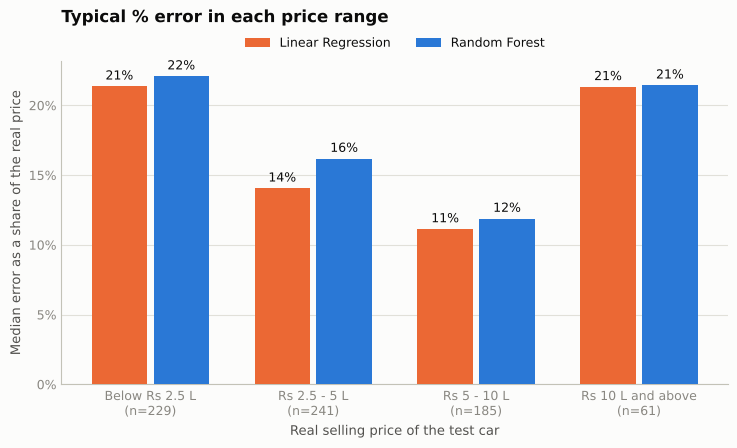

In [28]:
by_range = ev.errors_by_price_range(y_test, {k: preds[k] for k in REAL})
tbl = pd.DataFrame({label: {"cars": v["n"],
                            "Linear: MAE (Rs)": v["linear_regression"]["mae_rs"], "Linear: median % error": 100 * v["linear_regression"]["median_ape"],
                            "RF: MAE (Rs)": v["random_forest"]["mae_rs"], "RF: median % error": 100 * v["random_forest"]["median_ape"]}
                    for label, v in by_range.items()}).T
display(tbl.round({"cars": 0, "Linear: MAE (Rs)": 0, "Linear: median % error": 1, "RF: MAE (Rs)": 0, "RF: median % error": 1}))
_ = viz.fig_error_by_price_range(by_range)

The groups above are used **only to look at the errors** (the model itself never sees them). In *percentage* terms the cars
that are hardest to price are the cheapest (below Rs 2.5 lakh: typical error 21%)
and the most expensive (Rs 10 lakh and above: 21%); mid-range cars are priced best
(11% for Rs 5-10 lakh). In *rupees* the error grows with the price: the average miss is only
Rs 39,245 for cars below Rs 2.5 lakh but Rs 378,607 for cars of Rs 10 lakh and above.
Likely reasons (we did not test them separately): on a cheap car a small absolute gap is a large percentage and the
car's condition matters most, which our data does not contain; luxury cars are rare (61 in the test set), so there is little to learn from.

### Learning curves: would more data help?

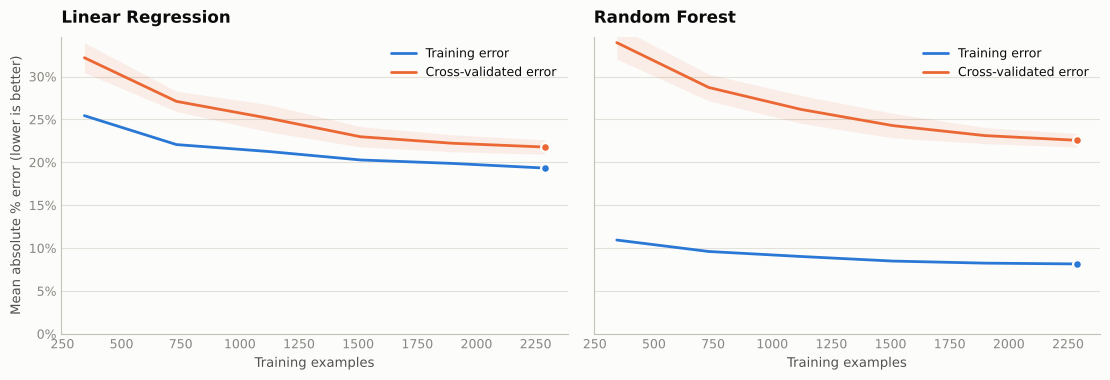

In [29]:
_ = viz.fig_learning_curve(mf.compute_learning_curves(models, X_train, y_train))

The curves show the average % error on the cars the model was trained on and on cars it had not seen, as the training
set grows.

**Random Forest:** training error is only about 8% while cross-validated error is about 23%, a gap of roughly 14 points. That is
overfitting: the forest partly memorises its training cars. The validation curve is still falling slowly, so more data
would help.

**Linear Regression:** training error is about 19% and cross-validated error about 22%, a gap of only about 3 points. Its
curves are flattening, so it is limited by what the 7 inputs can express rather than by too little data.

### Did the model perform satisfactorily?
**Yes, as a classroom-scale price estimator, with clear caveats.** Linear Regression explains about 87% of the variation in
price (R² 0.87, 95% interval 0.83-0.91) and prices half of the cars within 16% of the real value. R² of 0.80-0.85 is
what the papers in our survey report for this kind of data (for example R² 0.84 for Random Forest and 0.80 for Linear Regression in
Li, 2025), though those use different datasets and splits, so the numbers are not directly comparable. It is **not a valuation tool**: individual
estimates can be off by 30% or more, which is why the app shows the likely range.

### Limitations
* **2020 prices only.** The listings are from 2020; the model cannot price newer cars or today's market, and car age
  is measured against 2020.
* **Only 7 inputs.** No condition, accident history, colour, location, engine size or service record. Two cars
  with the same inputs can have very different prices.
* **Listing prices, not confirmed sale prices.** The data records the price on the listing, not necessarily what a buyer finally paid.
* **Typical error of about 15%, and larger for the cheapest and the most expensive cars.**
* **Small data.** 3,577 clean rows; some brands and models have only a handful of listings, and very expensive cars are rare.
* **A different market is priced too low** (external check, experiment C below): on another file with a much higher price level the model under-prices.
* **Brand tiers are our own judgement** (documented in `src/config.py`).

### Possible improvements
* Better inputs: on the larger v3 file, adding engine size, power, mileage and seats improves the typical error by roughly
  1 point (experiment B). Condition, accident history and location are probably more valuable still, but are not in any file we have.
* Gradient boosting (XGBoost / LightGBM). In a quick development prototype it did not beat Linear Regression on this data, so we kept two models.
* Collect fresh, dated listings and add a time or inflation adjustment.

### Bonus experiments (beyond the rubric)
These were run by `python -m src.experiments` and saved in `reports/experiments.json`. None of them changes the main results.

B. Richer features on the larger v3 file (6,925 clean rows, 1,385 test cars): does engine size / power / mileage / seats help?


,"R2, core 7 features","R2, + specs","MAE (Rs), core","MAE (Rs), + specs","mean % error, core","mean % error, + specs",improvement (pts),95% interval (pts)
Linear Regression,0.845,0.876,"77,827","73,438",16.7,15.9,0.7,+0.5 to +1.0
Random Forest,0.847,0.901,"82,521","71,959",17.4,16.2,1.2,+0.7 to +1.7


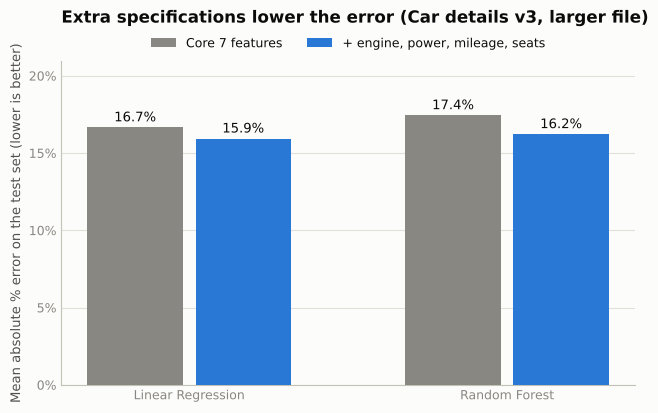

In [30]:
rich = exp["richer_features_v3"]
print(f"B. Richer features on the larger v3 file ({rich['rows_clean']:,} clean rows, {rich['rows_test']:,} test cars): "
      "does engine size / power / mileage / seats help?")
rich_tbl = pd.DataFrame({names_[k]: {"R2, core 7 features": v["base_r2"], "R2, + specs": v["extended_r2"],
                                     "MAE (Rs), core": v["base_mae_rs"], "MAE (Rs), + specs": v["extended_mae_rs"],
                                     "mean % error, core": 100 * v["base_mape"], "mean % error, + specs": 100 * v["extended_mape"],
                                     "improvement (pts)": v["mape_reduction_points"],
                                     "95% interval (pts)": f"{v['mape_reduction_ci95_points'][0]:+.1f} to {v['mape_reduction_ci95_points'][1]:+.1f}"}
                         for k, v in rich["results"].items()}).T
display(rich_tbl.style.format({"R2, core 7 features": "{:.3f}", "R2, + specs": "{:.3f}", "MAE (Rs), core": "{:,.0f}",
                               "MAE (Rs), + specs": "{:,.0f}", "mean % error, core": "{:.1f}", "mean % error, + specs": "{:.1f}",
                               "improvement (pts)": "{:.1f}"}))
_ = viz.fig_richer_features(rich)

**Result: a modest but real gain.** Adding engine size, power, mileage and seats lowers the mean % error by
0.7 points for Linear Regression (95% interval +0.5 to +1.0) and by
1.2 points for Random Forest (+0.7 to +1.7); both intervals exclude zero. R² rises from
0.84 to 0.88 (Linear) and from 0.85 to 0.90 (Random Forest), so the forest benefits more from the extra columns.
The absolute numbers come from a different, larger file and split, so do not compare them with the main results. The main
project keeps the seven original inputs because that is what the CarDekho file provides and what a user can easily type in.

C. External check on a different file, with another layout and higher prices (v4, 2,032 cars, median price Rs 825,000 vs Rs 350,000 in our data)


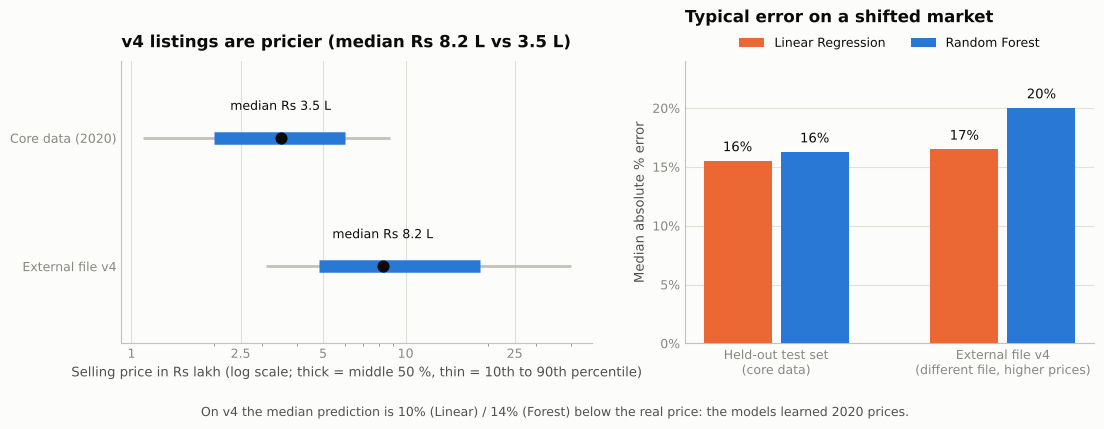

In [31]:
ext = exp["external_validation_v4"]
print(f"C. External check on a different file, with another layout and higher prices (v4, {ext['rows']:,} cars, "
      f"median price Rs {ext['median_price_v4']:,.0f} vs Rs {ext['median_price_main']:,.0f} in our data)")
_ = viz.fig_external_validation(ext)

**How to read this.** The v4 file has a different layout and a much higher price level: its median price is
Rs 8.2 lakh against Rs 3.5 lakh in our data. Our models, trained on cheaper 2020 listings, **under-price** these cars:
68% (Linear) and 72% (Random Forest) of v4 cars get a price below the real one, with a median bias of
-10% and -14%. R² in rupees collapses to 0.38 (Linear) and 0.30 (Random Forest) and the average miss grows to
Rs 5.8 lakh and Rs 6.6 lakh, mainly because these cars cost more. The *typical* percentage error rises only moderately,
from 16% to 17% (Linear) and from 16% to 20% (Random Forest), and Linear Regression
generalises better than Random Forest here too. The lesson: the model learned **the 2020 CarDekho market**; it does not carry
over to a market with a different price level unless it is re-trained. This is the main limitation to mention in the viva.

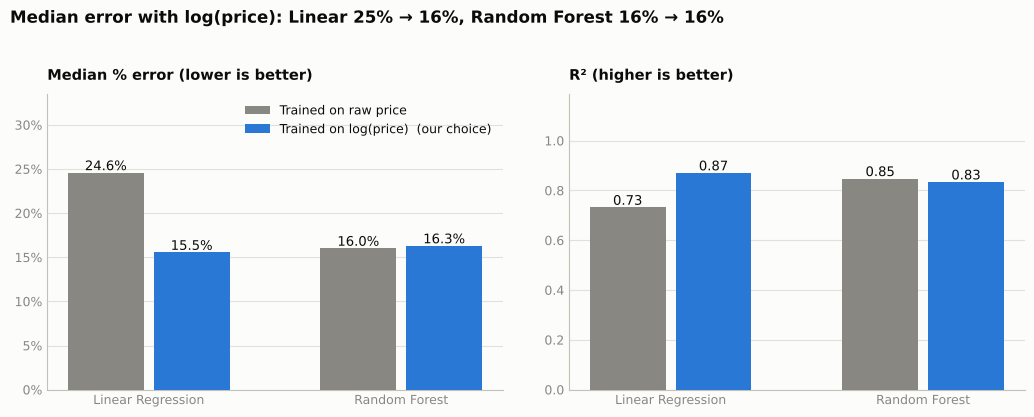

In [32]:
_ = viz.fig_log_vs_raw(exp["log_vs_raw_target"])

**D. Does predicting log(price) matter?** For Linear Regression, yes: with the log the typical error is 15.5%
and R² 0.871; predicting the raw price instead gives 24.6% and R²
0.733, and 38 test cars get a **negative price**. For Random Forest it makes
almost no difference (typical error 16.3% with the log, 16.0% without),
because trees only average prices that exist in the data. We use the log for both so the comparison is fair and no
price can be negative.

---
## Part 5 · Live demonstration, team contribution and viva &nbsp;(2 marks)

### Live demo (Streamlit web app)
From the repo folder run:

```bash
pip install -r requirements.txt
streamlit run app/streamlit_app.py
```

The app takes a car's details and returns the **estimated price in rupees**, the likely range, the second model's estimate,
a "why this price?" chart and comparable real listings. Below is the same prediction logic called from Python.

In [33]:
best = models["linear_regression"]                  # chosen by cross-validated RMSLE (see Part 3)
reference = pr.typical_reference(clean_df)
demo = [  # brand, model, variant, year, km, fuel, seller, transmission, owner
    ("Maruti",  "Alto 800", "LXI",       2012,  90_000, "Petrol", "Individual", "Manual",    "Second Owner"),
    ("Hyundai", "I20",      "Sportz",    2016,  45_000, "Petrol", "Individual", "Manual",    "First Owner"),
    ("Toyota",  "Innova",   "2.5 Z",     2015,  80_000, "Diesel", "Individual", "Manual",    "First Owner"),
    ("Honda",   "City",     "ZX CVT",    2018,  20_000, "Petrol", "Dealer",     "Automatic", "First Owner"),
    ("BMW",     "3 Series", "320d Luxury", 2017, 40_000, "Diesel", "Dealer",     "Automatic", "First Owner"),
]
rows = []
for brand, model, variant, year, km, fuel, seller, trans, owner in demo:
    x = pr.build_input(brand, model, variant, year, km, fuel, seller, trans, owner)
    p_lin, p_rf = pr.predict_price(models["linear_regression"], x), pr.predict_price(models["random_forest"], x)
    lo, hi = pr.likely_range(p_lin, intervals["linear_regression"])
    rows.append({"car": f"{brand} {model} {variant} ({year}, {km:,} km)", "Linear Regression": pr.inr(p_lin),
                 "likely range": f"{pr.inr(lo)} to {pr.inr(hi)}", "Random Forest": pr.inr(p_rf)})
display(pd.DataFrame(rows).style.hide(axis="index"))

x = pr.build_input("Hyundai", "I20", "Sportz", 2016, 45_000, "Petrol", "Individual", "Manual", "First Owner")
price = pr.predict_price(best, x)
print(f"\nWhy {pr.inr(price)} for the Hyundai i20? (change in the estimate, in rupees, when each input is replaced by a typical car's value)")
display(pr.explain_by_occlusion(best, x, reference).round(0))
print("Comparable real listings (price in lakh):")
display(pr.comparable_listings(clean_df, "Hyundai", "I20", 2016))

car,Linear Regression,likely range,Random Forest
"Maruti Alto 800 LXI (2012, 90,000 km)","Rs 1,32,000","Rs 93,000 to Rs 1,80,000","Rs 1,99,000"
"Hyundai I20 Sportz (2016, 45,000 km)","Rs 5,26,000","Rs 3,73,000 to Rs 7,20,000","Rs 5,23,000"
"Toyota Innova 2.5 Z (2015, 80,000 km)","Rs 10,55,000","Rs 7,47,000 to Rs 14,43,000","Rs 9,67,000"
"Honda City ZX CVT (2018, 20,000 km)","Rs 9,19,000","Rs 6,51,000 to Rs 12,57,000","Rs 9,43,000"
"BMW 3 Series 320d Luxury (2017, 40,000 km)","Rs 29,27,000","Rs 20,72,000 to Rs 40,02,000","Rs 28,10,000"



Why Rs 5,26,000 for the Hyundai i20? (change in the estimate, in rupees, when each input is replaced by a typical car's value)


,input,effect_rs
0,Year,134520.0
1,Fuel,-118730.0
2,"Brand, model and variant",78166.0
3,Km driven,12017.0
4,Seller type,0.0
5,Transmission,0.0
6,Owner,0.0


Comparable real listings (price in lakh):


,name,year,km_driven,fuel,transmission,owner,price_lakh
0,Hyundai i20 Asta 1.4 CRDi,2016,20000,Diesel,Manual,First Owner,6.80
1,Hyundai i20 Active SX Petrol,2016,23000,Petrol,Manual,First Owner,5.50
2,Hyundai i20 Magna 1.2,2016,25000,Petrol,Manual,First Owner,6.00
3,Hyundai i20 Sportz Option 1.2,2016,25000,Petrol,Manual,First Owner,4.75
4,Hyundai i20 Asta Option 1.2,2016,25000,Petrol,Manual,First Owner,6.00
5,Hyundai i20 Active 1.2 SX,2016,26000,Petrol,Manual,First Owner,6.50
6,Hyundai i20 Active 1.2 SX,2016,30000,Petrol,Manual,First Owner,6.00
7,Hyundai i20 1.2 Magna Executive,2016,38365,Petrol,Manual,First Owner,5.35


### Team contribution
| Student | Responsibility | Where to find it |
|---|---|---|
| **Student 1 · Abdul Rafe (2407070)** | Dataset description and preprocessing | Parts 1-2, `src/data_prep.py`, `src/features.py` |
| **Student 2 · Muntasir Ali Khan (2407019)** | ML model implementation | Part 3, `src/pipeline.py`, `src/train.py` |
| **Student 3 · Shaikh Abdullah Saud (2407040)** | Model evaluation, results and overall demonstration | Parts 4-5, `src/evaluate.py`, `app/streamlit_app.py` |

Viva preparation (expected questions with short answers) is in `docs/VIVA_GUIDE.md`.

### Reproducibility check

In [34]:
saved = json.loads(cfg.METRICS_PATH.read_text())["models"]
ok = True
for k in REAL:
    for metric in ("r2", "mae_rs", "median_ape"):
        same = abs(saved[k][metric] - results[k][metric]) < 1e-6 * max(1.0, abs(saved[k][metric]))
        ok &= same
        print(f"{k:20s} {metric:11s} notebook {results[k][metric]:14.4f}   saved report {saved[k][metric]:14.4f}   {'match' if same else 'DIFFERENT'}")
    for side in ("lower_multiplier", "upper_multiplier"):
        same = abs(saved[k]["likely_range"][side] - intervals[k][side]) < 1e-6
        ok &= same
        print(f"{k:20s} {side:16s} notebook {intervals[k][side]:9.4f}   saved report {saved[k]['likely_range'][side]:9.4f}   {'match' if same else 'DIFFERENT'}")
print("\nAll numbers match the saved report." if ok else
      "\nSome numbers differ. This can happen with a different scikit-learn version; the code is unchanged.")

linear_regression    r2          notebook         0.8710   saved report         0.8710   match
linear_regression    mae_rs      notebook     89211.8187   saved report     89211.8187   match
linear_regression    median_ape  notebook         0.1554   saved report         0.1554   match
linear_regression    lower_multiplier notebook    0.7079   saved report    0.7079   match
linear_regression    upper_multiplier notebook    1.3673   saved report    1.3673   match
random_forest        r2          notebook         0.8344   saved report         0.8344   match
random_forest        mae_rs      notebook     98562.0502   saved report     98562.0502   match
random_forest        median_ape  notebook         0.1629   saved report         0.1629   match
random_forest        lower_multiplier notebook    0.7110   saved report    0.7110   match
random_forest        upper_multiplier notebook    1.3976   saved report    1.3976   match

All numbers match the saved report.
